In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
df=pd.read_csv('/content/Fish.csv')
df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [ ]:
df = df.drop(columns=['Species','Length1','Length2','Height','Width',])
display(df.head())

,Weight,Length3
0,242.0,30.0
1,290.0,31.2
2,340.0,31.1
3,363.0,33.5
4,430.0,34.0


In [ ]:
df.shape

(159, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Weight   159 non-null    float64
 1   Length3  159 non-null    float64
dtypes: float64(2)
memory usage: 2.6 KB


In [ ]:
df.describe()

,Weight,Length3
count,159.000000,159.000000
mean,398.326415,31.227044
std,357.978317,11.610246
min,0.000000,8.800000
25%,120.000000,23.150000
50%,273.000000,29.400000
75%,650.000000,39.650000
max,1650.000000,68.000000


In [ ]:
df.isnull().sum()

,0
Weight,0
Length3,0


In [ ]:
#duplicates
print(df.duplicated().sum())
# Remove duplicates if any
df.drop_duplicates(inplace=True)

5


<Axes: ylabel='Weight'>

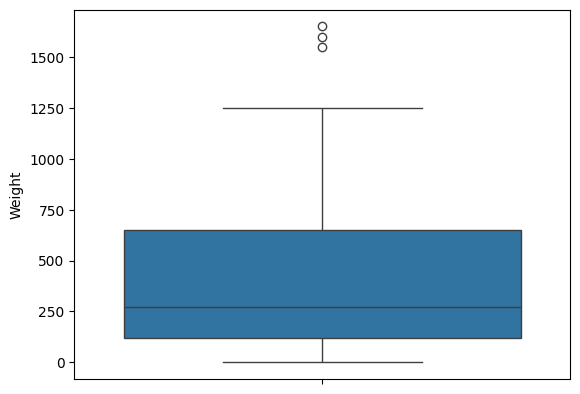

In [ ]:
#Outlier detection
sns.boxplot(df['Weight'])

In [ ]:
#dependent&independent variable
x=df['Length3'] #df.iloc[:,0].values
y=df['Weight'] #df.iloc[:,1].values

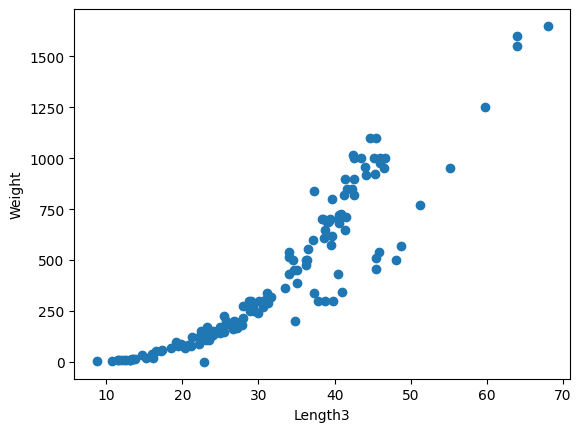

In [ ]:
#rln b/w dependent&non-dependent is Linear/non-linear
plt.scatter(x,y)
plt.xlabel('Length3')
plt.ylabel('Weight')
plt.show()

In [ ]:
# Split the dataset into training and testing sets
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
print(f"Number of instances for training: {len(x_train)}")
print(f"Number of instances for testing: {len(x_test)}")

Number of instances for training: 123
Number of instances for testing: 31


In [ ]:
polynomial_features=PolynomialFeatures(degree=2)

In [ ]:
x_poly=polynomial_features.fit_transform(x.to_frame())

In [ ]:
#Model Building
lr_model=LinearRegression()
lr_model.fit(x_poly,y)

LinearRegression()

In [ ]:
model=LinearRegression()
model.fit(x_train.values.reshape(-1,1),y_train)

LinearRegression()

In [ ]:
#Model Training
x_train_poly = polynomial_features.transform(x_train.to_frame())
model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
#Predictions
y_pred=lr_model.predict(x_poly)
df=pd.DataFrame({'Actual':y,'Predicted':y_pred})
print(df)

     Actual   Predicted
0     242.0  325.385561
1     290.0  357.415899
2     340.0  354.714143
3     363.0  421.190240
4     430.0  435.468638
..      ...         ...
154    12.2  -30.236431
155    13.4  -28.582542
156    12.2  -23.585355
157    19.7    0.439346
158    19.9   18.310266

[154 rows x 2 columns]


In [ ]:
#Evaluation metrics on training dataset
print("Model Evaluation Metrics on Training Dataset:")
y_train_pred = model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("  Mean Absolute Error (MAE):", mae)
print("  Mean Squared Error (MSE):", mse)
print("  Root MSE (RMSE):", rmse)
print("  R2 Score:", r2)

Model Evaluation Metrics on Training Dataset:
  Mean Absolute Error (MAE): 85.94463542479956
  Mean Squared Error (MSE): 16414.98453975076
  Root MSE (RMSE): 128.1209761895013
  R2 Score: 0.8524718409459426


In [ ]:
#Evaluation metrics on testing dataset
print("Model Evaluation Metrics on Testing Dataset:")
x_test_poly = polynomial_features.transform(x_test.to_frame())
y_test_pred = model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("  Mean Absolute Error (MAE):", mae)
print("  Mean Squared Error (MSE):", mse)
print("  Root MSE (RMSE):", rmse)
print("  R2 Score: ", r2)

Model Evaluation Metrics on Testing Dataset:
  Mean Absolute Error (MAE): 89.58609136326217
  Mean Squared Error (MSE): 16618.148589682092
  Root MSE (RMSE): 128.91139821475093
  R2 Score:  0.9162367257407587


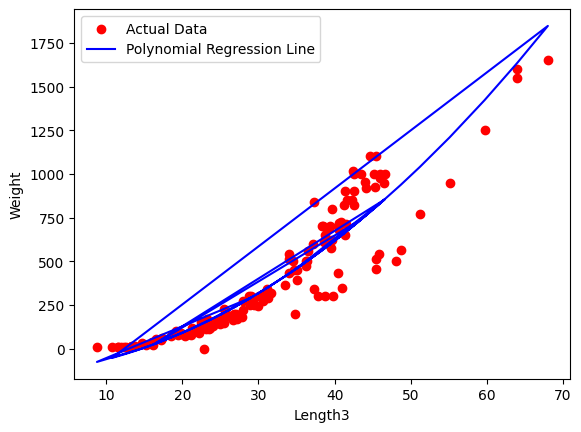

In [ ]:
plt.scatter(x,y,color='red',label='Actual Data')
plt.plot(x,model.predict(polynomial_features.transform(x.to_frame())),color='blue',label='Polynomial Regression Line')
plt.legend()
plt.xlabel('Length3')
plt.ylabel('Weight')
plt.show()